# A puzzle made of glued blocks

![the puzzle](img/glued_blocks_puzzle.png)

Missing lines between stickers mean the two cubies are glued. Reading the separator lines off the
image gives every glued pair of stickers. Each glue between two cubies that show on two faces
appears on both faces, so the reading checks itself. The bandage is:

```
UBR+UR | UFL+UF | ULB+UB | UL+U | DRB+DR | DFR+FR | DLF+FL | DBL+BL | BR+R | DF+F | DL+L | DB+D+B
```

* **7 corner-edge blocks** (1x1x2): `UBR+UR`, `UFL+UF`, `ULB+UB` on top, `DRB+DR` on the bottom,
  `DFR+FR`, `DLF+FL`, `DBL+BL` standing vertically.
* **5 blocks holding a center**, which therefore never leave their face: `UL+U`, `BR+R`, `DF+F`,
  `DL+L`, `DB+D+B`.
* **one free piece**: the URF corner. Every other corner and edge is glued.

At the start only `R`, `U` and `F` can turn.

legal at start: R R2 R' U U2 U' F F2 F'


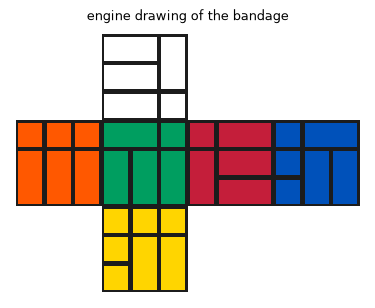

In [1]:
import collections
import pandas as pd
import matplotlib.pyplot as plt
import rubik

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
P = "UBR+UR | UFL+UF | ULB+UB | UL+U | DRB+DR | DFR+FR | DLF+FL | DBL+BL | BR+R | DF+F | DL+L | DB+D+B"
cube = rubik.Cube(bandage=P)
rubik.plot_cube(cube, title="engine drawing of the bandage", size=3.5)
print("legal at start:", " ".join(cube.legal_moves("htm")))

## Classic KPIs: they see nothing

The standard study (`rubik.difficulty`) measures 3-cycles, flips and twists of *unglued* pieces.
This puzzle has only one unglued piece, so every one of those is impossible. The size and distance
KPIs are still meaningful, and exact here because the whole puzzle fits in memory.

In [2]:
d = rubik.difficulty(P)
pd.Series({
    "reachable positions": f"{d['states']:,.0f}",
    "God's number (exact)": d["gods_number"],
    "mean optimal solution (exact)": round(d["mean_distance"], 2),
    "legal turns in a random position": round(d["branching"], 2),
    **{f"{k} possible": d[k]["possible"] for k in ["edge3", "corner3", "edge_flip", "corner_twist"]},
}).to_frame("value")

,value
reachable positions,"1,108,800"
God's number (exact),28
mean optimal solution (exact),18.8
legal turns in a random position,4.31
edge3 possible,0
corner3 possible,0
edge_flip possible,0
corner_twist possible,0


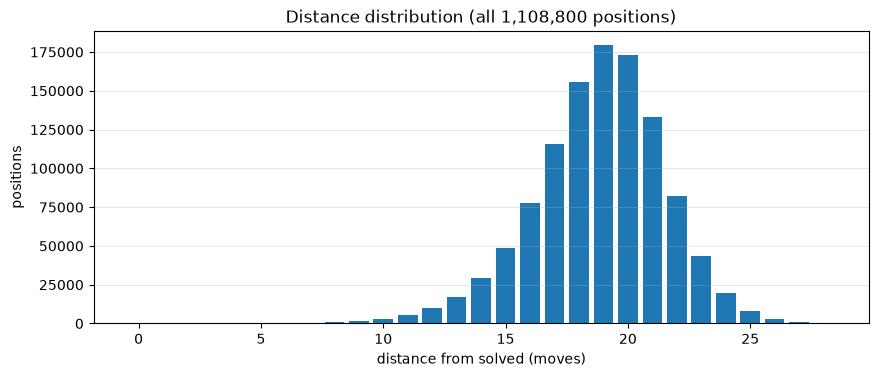

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(len(d["layer_sizes"])), d["layer_sizes"])
ax.set_xlabel("distance from solved (moves)"); ax.set_ylabel("positions"); ax.set_title("Distance distribution (all 1,108,800 positions)")
ax.grid(axis="y", alpha=.3)

## The block level

The engine now lets **blocks move**. A position counts as having the home shape when every block
sits on the home of a block of the same form (two congruent blocks can trade places), even if the
blocks have been exchanged. An algorithm may then permute blocks and is described by block cycles:
`(UBR+UR UFL+UF ULB+UB)` means the block at UBR+UR's home goes to UFL+UF's home, and so on.

Because this puzzle fits in memory, `Solver.home_shape_effects()` lists *every* home-shape position
with an optimal algorithm. These are all the block-level effects the puzzle has, each with its exact
shortest length.

In [4]:
import math
s = rubik.Solver(bandage=P, depth=100, max_nodes=5_000_000)
E = s.home_shape_effects(max_results=10**6)
n_home = len(E) + 1
moving = sorted({b for e in E for b in e["blocks"].replace("(", " ").replace(")", " ").split()})
print(f"home-shape positions: {n_home:,} = 7!/2 = {math.factorial(7)//2:,}")
print(f"distinct shapes: {s.num_states // n_home:,}  (positions / home-shape positions)")
print("free URF corner home whenever the shape is home:", all(e["free_solved"] for e in E))
print("blocks that ever move:", ", ".join(moving))

home-shape positions: 2,520 = 7!/2 = 2,520
distinct shapes: 440  (positions / home-shape positions)
free URF corner home whenever the shape is home: True
blocks that ever move: DBL+BL, DFR+FR, DLF+FL, DRB+DR, UBR+UR, UFL+UF, ULB+UB


**What this says.** At the block level the puzzle is exactly the even permutations of its 7
corner-edge blocks (the alternating group A₇, 2,520 elements):

* every even arrangement of the 7 blocks can be reached, and nothing else;
* a block's orientation is forced by where it sits;
* the free corner and the 5 center blocks always come home with the shape;
* a single swap of two blocks is impossible (odd), but two swaps at once or a 3-cycle are possible.

So solving it is two problems: steer through its 440 shapes, and put 7 blocks in order using
block 3-cycles and double swaps.

In [5]:
def ctype(e):
    return tuple(sorted((c.count("+") for c in e["blocks"].split(") (")), reverse=True))
names = {(3,): "3-cycle", (2, 2): "double swap", (5,): "5-cycle", (3, 3): "two 3-cycles",
         (7,): "7-cycle", (4, 2): "4-cycle + swap", (3, 2, 2): "3-cycle + 2 swaps"}
by = collections.defaultdict(list)
for e in E:
    by[ctype(e)].append(e)
rows = []
for t, l in sorted(by.items(), key=lambda x: min(e["length"] for e in x[1])):
    best = min(l, key=lambda e: e["length"])
    ls = [e["length"] for e in l]
    rows.append({"block effect": names.get(t, str(t)), "how many": len(l), "shortest": min(ls),
                 "mean": round(sum(ls) / len(ls), 1), "longest": max(ls), "a shortest one": best["blocks"], "algorithm": best["alg"]})
pd.DataFrame(rows)

,block effect,how many,shortest,mean,longest,a shortest one,algorithm
0,5-cycle,504,7,15.9,20,(UBR+UR DFR+FR DBL+BL UFL+UF DLF+FL),F' U L F U L' U2
1,double swap,105,8,16.3,20,(UBR+UR ULB+UB) (DFR+FR DBL+BL),R U' L U2 R' U L' U2
2,two 3-cycles,280,9,16.1,20,(UBR+UR ULB+UB DLF+FL) (UFL+UF DFR+FR DBL+BL),R U R' F2 L F2 U L' U2
3,3-cycle,70,9,13.4,17,(UBR+UR DFR+FR DLF+FL),R U R' F' U L F L' U2
4,7-cycle,720,10,17.5,21,(UBR+UR ULB+UB DBL+BL UFL+UF DRB+DR DFR+FR DLF+FL),R U F' L F2 R' F' U L' U2
5,4-cycle + swap,630,11,16.9,22,(UBR+UR UFL+UF) (ULB+UB DFR+FR DBL+BL DRB+DR),U2 L U2 R' F R2 U2 F' L' U2 R'
6,3-cycle + 2 swaps,210,13,17.7,21,(UBR+UR DBL+BL) (UFL+UF DLF+FL) (ULB+UB DFR+FR DRB+DR),F' U L F U' R' F R2 U2 F' L' U2 R'


### Block 3-cycles

The workhorse for a human solve, like corner and edge 3-cycles on a normal cube. All 35 triples
of blocks can be cycled in both directions (70 effects). The shortest take 9 moves, and the
hardest triple needs 17.

,moves,blocks,algorithm
0,9,(UBR+UR DFR+FR DLF+FL),R U R' F' U L F L' U2
1,9,(UBR+UR UFL+UF ULB+UB),F' U L F' L' F2 R U' R'
2,9,(UBR+UR ULB+UB UFL+UF),R U R' F2 L F L' U' F
3,9,(DRB+DR DFR+FR DLF+FL),R U2 L' U' L F U' R' F'
4,9,(DRB+DR DLF+FL DFR+FR),F R U F' L' U L U2 R'
5,9,(UBR+UR DLF+FL DFR+FR),U2 L F' L' U' F R U' R'
6,10,(UFL+UF ULB+UB DBL+BL),U L F2 R' F' R U F' L' U2
7,10,(UBR+UR DBL+BL DFR+FR),U2 L U2 R' F R U F' L' U'
8,10,(UBR+UR DFR+FR DBL+BL),U L F U' R' F' R U2 L' U2
9,10,(UFL+UF DBL+BL ULB+UB),U2 L F U' R' F R F2 L' U'


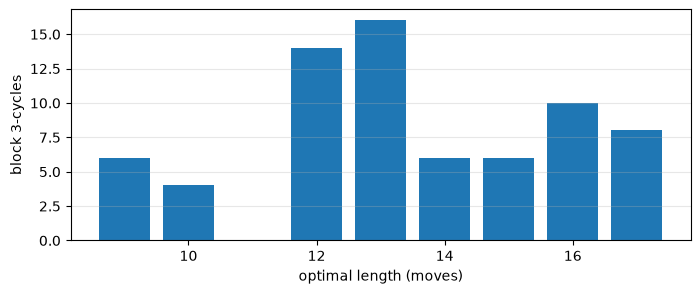

In [6]:
three = sorted(by[(3,)], key=lambda e: e["length"])
fig, ax = plt.subplots(figsize=(8, 3))
c = collections.Counter(e["length"] for e in three)
ax.bar(list(c), list(c.values())); ax.set_xlabel("optimal length (moves)"); ax.set_ylabel("block 3-cycles"); ax.grid(axis="y", alpha=.3)
pd.DataFrame([{"moves": e["length"], "blocks": e["blocks"], "algorithm": e["alg"]} for e in three[:12]])

### Seeing it

Each drawing is the puzzle after the algorithm, starting from solved. The dots mark the moved
pieces. The blocks keep their shape and their glue, they just trade homes.

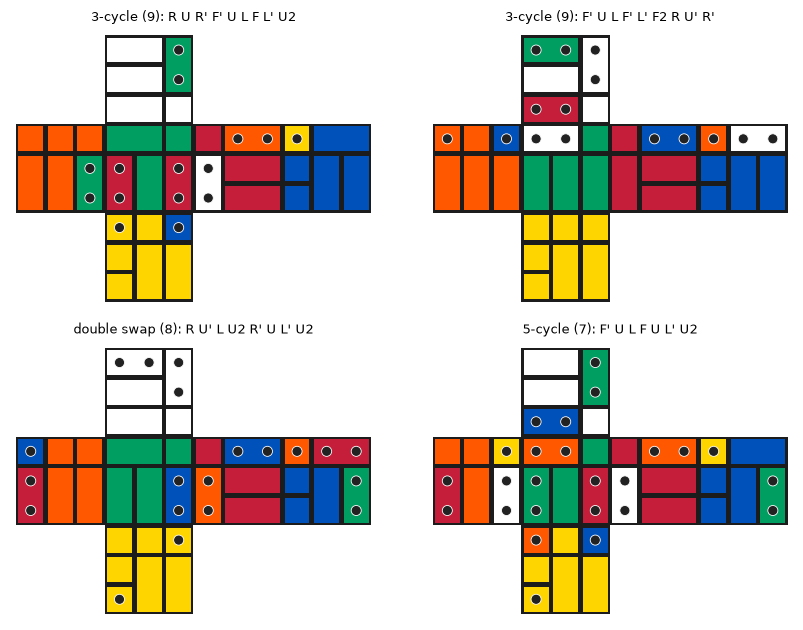

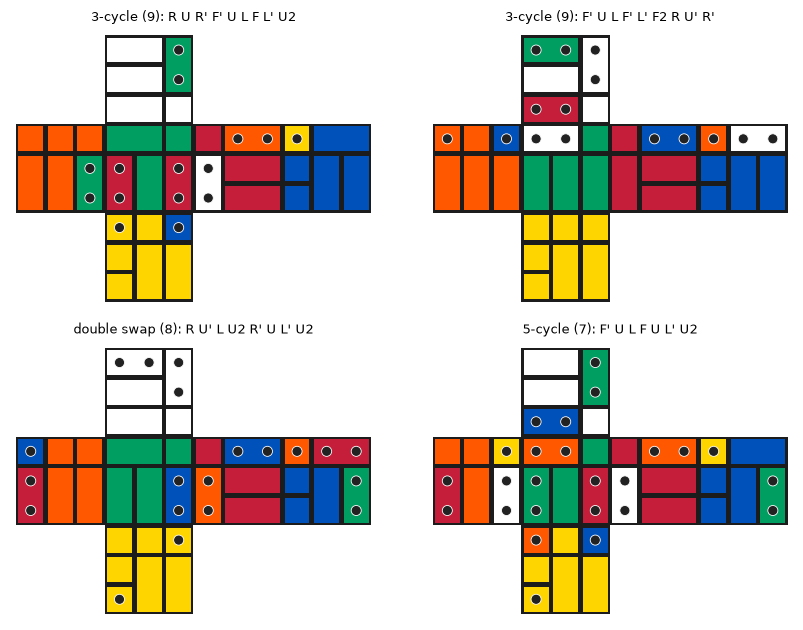

In [7]:
show = [three[0], three[1], min(by[(2, 2)], key=lambda e: e["length"]), min(by[(5,)], key=lambda e: e["length"])]
cubes = [rubik.Cube(bandage=P).apply(e["alg"]) for e in show]
for c, e in zip(cubes, show):
    assert c.blocks_moved() == e["blocks"]
rubik.plot_cubes(cubes, titles=[f"{names[ctype(e)]} ({e['length']}): {e['alg']}" for e in show],
                 highlights=[rubik.analyze(e["alg"], bandage=P)["affected"] for e in show], ncols=2, size=3.2)

## The same search on bigger puzzles

Listing every home-shape position only works when the whole puzzle fits in memory. For larger
bandages, `Solver.find(..., move_blocks=True)` searches block effects with the meet-in-the-middle
engine, exactly like edge and corner 3-cycles: name the blocks' cubies in `pieces`, and only those
may move. Here it finds the optimal 9-move 3-cycle of the three top blocks from a depth-5 table, in
well under a second.

In [8]:
small = rubik.Solver(bandage=P, depth=5)
found = small.find("any", pieces=["UBR", "UR", "UFL", "UF", "ULB", "UB"], move_blocks=True, max_results=5)
pd.DataFrame(found)[["alg", "length", "blocks", "effect"]]

,alg,length,blocks,effect
0,F' U L F' L' F2 R U' R',9,(UBR+UR UFL+UF ULB+UB),(UR* UF* UB) (UFL- ULB UBR+)
1,R U R' F2 L F L' U' F,9,(UBR+UR ULB+UB UFL+UF),(UR UB* UF*) (UFL- UBR ULB+)
2,R U R' F' U L' U' L F U',10,(UBR+UR ULB+UB UFL+UF),(UR UB* UF*) (UFL- UBR ULB+)
3,U F' L' U L U' F R U' R',10,(UBR+UR UFL+UF ULB+UB),(UR* UF* UB) (UFL- ULB UBR+)


## What this suggests for difficulty KPIs

For heavily bandaged puzzles the useful questions move up a level:

| KPI | this puzzle |
|---|---|
| block group: which arrangements of congruent blocks are reachable | A₇ on 7 corner-edge blocks (2,520) |
| shapes: how many forms the puzzle can take | 440 |
| shortest block 3-cycle (best and worst triple) | 9 / 17 |
| shortest block double swap | 8 |
| free pieces left to solve | 1 corner, always solved with the shape |
| God's number / mean solution | 28 / 18.8 (3x3x3: 20 / 17.7) |

The 1.1 million positions are 440 shapes × 2,520 block arrangements. For a solver, the hard part is
steering through the shapes and knowing a block 3-cycle, not the number of positions.